# Step 4. Apply

*With ngff-zarr.*

**Goal:** use the registration from the scene, without writing a resampled copy.

`pair.ozx` is enough for the image: the two images and the transformation travel together.

In [ ]:
from pathlib import Path

import ngff_zarr as nz
import numpy as np
from common import DATA, dice, ncc, overlay, scene_fields
from IPython.display import Image
from ngff_zarr.v06.zarr_metadata import Identity

OUTPUT, SCENE = Path("../output"), "../output/pair.ozx"

scene = nz.NgffScene.from_ome_zarr(SCENE)
transformation = scene.coordinateTransformations[0]
fixed, moving = scene.images["fixed"].images[0], scene.images["moving"].images[0]
fields = scene_fields(SCENE, transformation)  # a displacements field, read from the scene; nothing for an affine

# Lazy: this describes the result, block by block. Nothing is read or computed yet.
moved = nz.resample(transformation, fixed, moving, fields=fields)
moved.data

dask.array<ngff-zarr-resample, shape=(50, 680, 535), dtype=uint16, chunksize=(50, 128, 128), chunktype=numpy.ndarray>

`moved` is the moving image drawn on the fixed grid: for each voxel $x$ of the fixed image, the moving image read at
$T(x)$. It is a description, not an array: computing one plane reads only the part of the moving image that plane
needs. "Before" is the same call through the identity: the moving image on the fixed grid as the two sit in space.
Where the two rounds agree, green and magenta turn white:

Correlation with the fixed image, on one plane: -0.06 -> 0.90


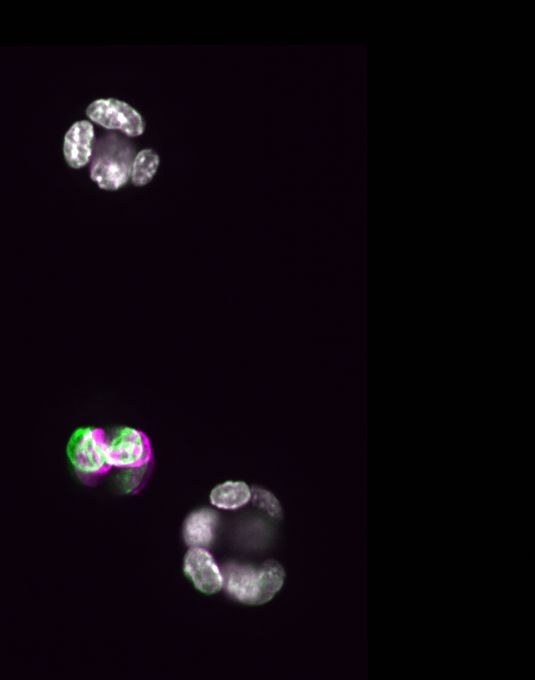

In [ ]:
unmoved = nz.resample(Identity(input=transformation.input, output=transformation.output), fixed, moving)

middle = fixed.data.shape[0] // 2
fixed_plane, moved_plane = np.asarray(fixed.data[middle]), np.asarray(moved.data[middle])
overlay(fixed_plane, moved_plane, OUTPUT / "after.png")

before = ncc(fixed_plane, np.asarray(unmoved.data[middle]))
print(f"Correlation with the fixed image, on one plane: {before:.2f} -> {ncc(fixed_plane, moved_plane):.2f}")
Image(OUTPUT / "after.png", width=340)

The scene keeps the pyramids, so the same works at any resolution. The whole organoid at the coarsest level, computed
in a moment:

In [ ]:
coarse = nz.resample(transformation, scene.images["fixed"].images[2], scene.images["moving"].images[2], fields=fields)
print(f"{' x '.join(str(extent) for extent in coarse.data.shape)} voxels, correlation on the middle plane: "
      f"{ncc(np.asarray(coarse.data[12]), np.asarray(scene.images['fixed'].images[2].data[12])):.2f}")

50 x 170 x 133 voxels, correlation on the middle plane: 0.98


## The same transformation carries everything else

Here the nuclei of each round, from the stores of step 1, with an interpolation that keeps their labels. The measure is
the Dice of the two nuclei masks, all nuclei against all nuclei: it says how well the nuclei overlap, not whether each
nucleus found its own.

In [ ]:
labels_fixed = nz.from_ngff_zarr(f"{DATA}/fixed_nuclei.ome.zarr").images[0]
labels_moving = nz.from_ngff_zarr(f"{DATA}/moving_nuclei.ome.zarr").images[0]

carried = nz.resample(transformation, fixed, labels_moving, interpolator="label_image", fields=fields)

before = dice(labels_fixed.data, labels_moving.data)
print(f"Binary nuclei mask Dice: {before:.2f} -> {dice(labels_fixed.data, carried.data):.2f}")

Binary nuclei mask Dice: 0.00 -> 0.92


## Map points

A landmark goes through the same transformation, without any image: a point of the fixed image, in micrometers and in
the order z, y, x, comes out at its place in the moving image.

In [ ]:
!echo '[[15.0, 73.0, 58.0]]' > ../output/points.json
!ngff-zarr transform-points ../output/pair.ozx ../output/points.json

{"dims": ["z", "y", "x"], "points": [[16.36255275177611, 63.190992652133474, 94.37253238054316]]}


## See it in napari

A viewer that reads RFC-5 does the same on its own. napari-ome-zarr opens the scene, builds the graph of its coordinate
systems, and places the moving image through the affine itself: the two rounds, green and magenta, in one view, with
nothing written. Scroll through the planes, zoom into the full resolution. A `displacements` field is not in
napari-ome-zarr yet: with a deformable preset, the pictures above are the way to look.

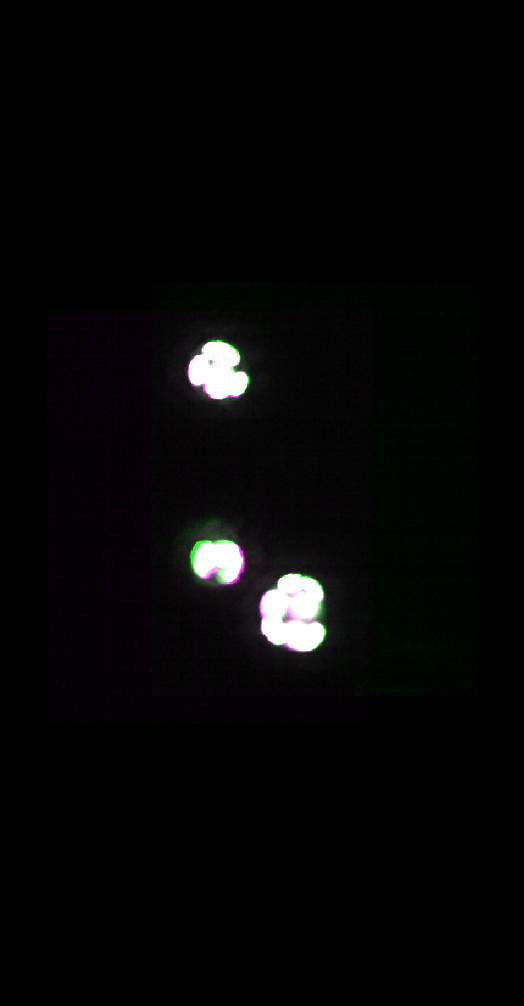

In [ ]:
import napari
from napari.utils import nbscreenshot

viewer = napari.Viewer()
viewer.open("../output/pair.ome.zarr", plugin="napari-ome-zarr")  # the scene as a folder, written beside pair.ozx
viewer.layers[0].colormap, viewer.layers[1].colormap = "green", "magenta"
for layer in viewer.layers:
    layer.blending = "additive"
viewer.dims.set_point(0, 15)  # the middle plane, in micrometers
viewer.window.resize(560, 500)
viewer.reset_view()
nbscreenshot(viewer, canvas_only=True)

## You are done

You started from two images of a public plate, and you have one file holding them and their registration, in the form
RFC-5 gives every OME-Zarr reader to apply: ngff-zarr applies it, napari shows it. **[Going further](../going-further.md)**:
your own pair, 2-D images, larger images.